In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [2]:
import pickle

In [3]:
with open('good_lines.pkl', 'rb') as f:
    good_lines = pickle.load(f) 

In [4]:
good_lines

[{'line_id': np.int64(41),
  'line_wl': np.float64(3898.5529464208234),
  'order_number': np.int64(3),
  'line_string': '3898.5529464208234_3',
  'line_depth': np.float64(0.8125255769296276)},
 {'line_id': np.int64(45),
  'line_wl': np.float64(3900.8139454679713),
  'order_number': np.int64(3),
  'line_string': '3900.8139454679713_3',
  'line_depth': np.float64(0.8880540852011862)},
 {'line_id': np.int64(50),
  'line_wl': np.float64(3902.6934833013465),
  'order_number': np.int64(3),
  'line_string': '3902.6934833013465_3',
  'line_depth': np.float64(0.633774212081829)},
 {'line_id': np.int64(64),
  'line_wl': np.float64(3908.5755568083014),
  'order_number': np.int64(3),
  'line_string': '3908.5755568083014_3',
  'line_depth': np.float64(0.7793696684192339)},
 {'line_id': np.int64(89),
  'line_wl': np.float64(3916.3154078721086),
  'order_number': np.int64(4),
  'line_string': '3916.3154078721086_4',
  'line_depth': np.float64(0.401288432513579)},
 {'line_id': np.int64(167),
  'line_w

In [5]:
#find line ids that occur more than once
line_ids=[line['line_id'] for line in good_lines]
from collections import Counter
line_id_counts = Counter(line_ids)
duplicate_line_ids = np.array([line_id for line_id, count in line_id_counts.items() if count > 1])
print(duplicate_line_ids, len(duplicate_line_ids))
print(len(duplicate_line_ids))

[ 294  302  312  430  434  437  563  567  572  573  649  694  697  708
  831  833  840  845  850  857  863  895  963  964  969  973  981 1090
 1095 1099 1100 1101 1112 1115 1124 1128 1129 1130 1136 1212 1241 1247
 1254 1257 1267 1275 1284 1288 1399 1400 1411 1420 1424 1425 1429 1431
 1438 1551 1555 1556 1560 1565 1566 1571 1684 1695 1707 1710 1803 1818
 1826 1843 1846 1955 1956 1962 2067 2086 2087 2208 2209 2213 2228 2241
 2396 2397 2400 2402 2404 2523 2528 2549 2655 2660 2662 2667 2676 2678
 2683 2685 2785 2787 2788 2795 2797 2798 2802 2804 2811 2812 2867 2894
 2897 2898 2900 2901 2902 2910 2911 2912 2917 2921 2922 2924 3009 3011
 3016 3019 3023 3026 3033 3034 3036 3121 3122 3123 3132 3134 3136 3139
 3140 3141 3144 3145 3147 3235 3236 3237 3238 3239 3241 3243 3247 3248
 3249 3252 3321 3330 3334 3335 3336 3341 3342 3343 3345 3347 3348 3432
 3436 3439 3440 3442 3448 3449 3452 3453 3454 3528 3530 3532 3534 3535
 3537 3538 3542 3543 3549 3616 3617 3618 3620 3622 3623 3624 3628 3629
 3631 

In [6]:
corrs_w_unc_file='corrs_w_uncs_mc.pkl'
with open(corrs_w_unc_file, 'rb') as f:
    corrs_w_uncs = pickle.load(f)

In [7]:
len(corrs_w_uncs['amps'])

1292

In [8]:
len(good_lines)

1292

In [9]:
i1s=[]
i2s=[] 
for dup_line in duplicate_line_ids:
    i1=None
    i2=None
    for i, line in enumerate(good_lines):
        if line['line_id'] == dup_line:
            if i1 is None:
                i1 = i
            else:
                i2 = i
            #print(f"Duplicate line found at index {i}: {line['line_id']}")
    print(f"Indices for duplicate line {dup_line}: i1={i1}, i2={i2}")
    i1s.append(i1)
    i2s.append(i2)

Indices for duplicate line 294: i1=12, i2=13
Indices for duplicate line 302: i1=16, i2=17
Indices for duplicate line 312: i1=18, i2=19
Indices for duplicate line 430: i1=22, i2=23
Indices for duplicate line 434: i1=24, i2=25
Indices for duplicate line 437: i1=26, i2=27
Indices for duplicate line 563: i1=35, i2=36
Indices for duplicate line 567: i1=37, i2=38
Indices for duplicate line 572: i1=40, i2=41
Indices for duplicate line 573: i1=42, i2=43
Indices for duplicate line 649: i1=44, i2=45
Indices for duplicate line 694: i1=53, i2=54
Indices for duplicate line 697: i1=55, i2=56
Indices for duplicate line 708: i1=57, i2=58
Indices for duplicate line 831: i1=63, i2=64
Indices for duplicate line 833: i1=65, i2=66
Indices for duplicate line 840: i1=68, i2=69
Indices for duplicate line 845: i1=70, i2=71
Indices for duplicate line 850: i1=72, i2=73
Indices for duplicate line 857: i1=74, i2=75
Indices for duplicate line 863: i1=76, i2=77
Indices for duplicate line 895: i1=88, i2=89
Indices fo

Text(0, 0.5, 'center correlation from second order')

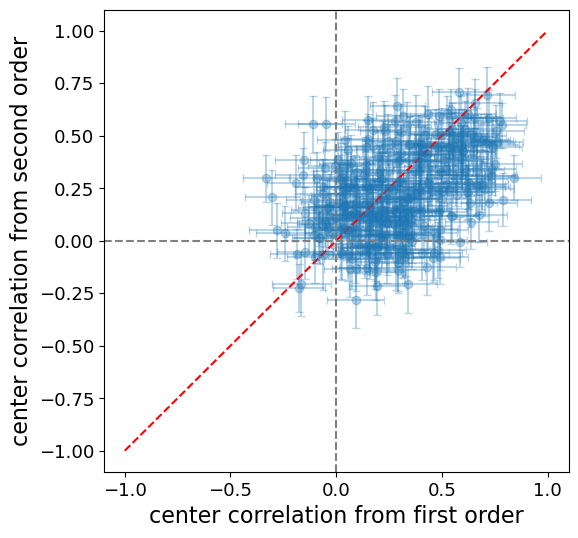

In [18]:
key='cens'
plt.figure(figsize=(6,6))
cens_1=np.array([corrs_w_uncs[key][i1] for i1 in i1s])
cens_1_unc=np.array([corrs_w_uncs[key+'_unc'][i1] for i1 in i1s])
cens_2=np.array([corrs_w_uncs[key][i2] for i2 in i2s])
cens_2_unc=np.array([corrs_w_uncs[key+'_unc'][i2] for i2 in i2s])
plt.errorbar(cens_1, cens_2, xerr=cens_1_unc, yerr=cens_2_unc, fmt='o',alpha=.3)
#plot y=x line for reference
plt.plot([-1, 1], [-1, 1], 'r--')
#plot x=0, y=0 lines for reference
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('cens_1')
plt.ylabel('cens_2')
plt.xlabel('center correlation from first order')
plt.ylabel('center correlation from second order')


In [11]:
#find points that deviate significantly from the y=x line
distance_from_y_eq_x = cens_2-cens_1
#calculate distance from line in sigmas
distance_from_y_eq_x_in_sigmas = distance_from_y_eq_x/np.sqrt(cens_1_unc**2 + cens_2_unc**2)
distance_from_y_eq_x_in_sigmas

array([-2.15105748,  1.63391433,  0.70816237,  1.21092842, -1.02752275,
       -0.00953717, -0.45611225,  0.4866935 , -0.74440675,  2.01018333,
       -0.12668623,  0.13936959,  0.41540377,  0.32251879,  2.76012262,
        0.96014196, -1.64877398,  0.4686788 , -0.01491292,  1.11201405,
        0.79425419, -2.54221762, -2.30262919, -1.09425782,  1.06928476,
        1.65786395,  1.2738551 , -0.02508742, -1.02776322,  0.0309191 ,
       -1.81967434,  0.69894521, -0.14623469, -1.29367436, -0.06908728,
        0.94028925,  0.43597214, -0.37135172,  0.19050399, -0.12630534,
       -2.09948677, -2.55506907, -1.50976647, -0.4427915 , -2.08397456,
        0.70271979,  0.44097285,  2.12390392, -0.08304063, -2.42914323,
        0.68963007, -0.41903399,  1.70015911, -0.90696629, -0.20263697,
        1.64024852,  1.56965691, -0.78197928, -0.48160271,  1.08508714,
        0.04800141, -1.16886085,  1.73068995, -0.25251796, -1.88757121,
       -2.97525708, -0.95221408,  1.60816441, -2.88751493,  0.29

In [12]:
distance_from_y_eq_x_in_sigmas >3

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [16]:
off_lines = duplicate_line_ids[np.where(distance_from_y_eq_x_in_sigmas > 2)[0]]

print(off_lines)
print(len(off_lines))

[ 573  831 1288 2683 2867 3033 3252 3549 4044 4395 4487 4554 4726 4828]
14


In [17]:
off_lines = duplicate_line_ids[np.where(distance_from_y_eq_x_in_sigmas > 3)[0]]

print(off_lines)
print(len(off_lines))

[2683 2867 4828]
3


In [14]:
len(distance_from_y_eq_x_in_sigmas)

343

In [15]:
len(duplicates_line_ids)

NameError: name 'duplicates_line_ids' is not defined